# A look at the Scoliosis1K data (EDA)

Before reading the training results, I want to know what the model actually sees. This notebook opens the silhouette release in `Scoliosis1K-sil-pkl/` and the four split files next to it, and checks, step by step:

1. what is on disk and whether every file has the same shape
2. how many children are in each class
3. the four train / test splits, and whether they leak
4. what one sequence looks like, frame by frame
5. simple pixel statistics: how much of the frame is body, and are there empty frames
6. the average silhouette of each class, and where the classes differ
7. a left–right asymmetry number per child, compared between classes

Everything here is read-only: nothing in `Scoliosis1K-sil-pkl/` is changed.

In [1]:
from pathlib import Path
import json, pickle
import numpy as np
import matplotlib.pyplot as plt

HERE = Path.cwd()                        
assert HERE.name == 'datasets', f'Open this notebook from reproduce/datasets, not {HERE}'
DATASET_ROOT = HERE / 'Scoliosis1K-sil-pkl'
SPLITS = sorted(HERE.glob('Scoliosis1K_*.json'), key=lambda p: int(p.stem.split('_')[1][2:]))   # 112, 114, 118, 1116
assert DATASET_ROOT.is_dir(), 'Unzip Scoliosis1K-sil-pkl.zip here first (see README.md)'

LABELS = ['negative', 'neutral', 'positive']
COLORS = {'negative': 'blue', 'neutral': 'red', 'positive': 'green'}

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '0.9', 'axes.axisbelow': True})
print('dataset :', DATASET_ROOT)
print('splits  :', [p.name for p in SPLITS])

dataset : c:\Users\ASUS\.vscode\OpenGait\checkpoint_1\reproduce\datasets\Scoliosis1K-sil-pkl
splits  : ['Scoliosis1K_112.json', 'Scoliosis1K_114.json', 'Scoliosis1K_118.json', 'Scoliosis1K_1116.json']


## 1. What is on disk

The folder name tells me everything about a sequence: `<id>/<class>/<view>/<view>.pkl`. I list all of them, then open every pkl once to check its shape and type. While each one is open I also keep the numbers I need later (sections 5–7), so I only read the 1,493 files one time.

In [2]:
pkls = sorted(DATASET_ROOT.glob('*/*/*/*.pkl'))
seqs = [dict(id=p.parts[-4], label=p.parts[-3], view=p.parts[-2], path=p) for p in pkls]

print('pkl files      :', len(seqs))
print('unique ids     :', len({s['id'] for s in seqs}))
print('classes        :', sorted({s['label'] for s in seqs}))
print('views          :', sorted({s['view'] for s in seqs}))

pkl files      : 1493
unique ids     : 1493
classes        : ['negative', 'neutral', 'positive']
views          : ['000_180']


In [3]:
shapes, dtypes = {}, set()
gei_sum = {l: np.zeros((64, 64)) for l in LABELS}

for i, s in enumerate(seqs):
    x = pickle.load(open(s['path'], 'rb')) # (T, 64, 64) uint8, 0 or 255
    shapes[x.shape] = shapes.get(x.shape, 0) + 1
    dtypes.add((x.dtype, x.min(), x.max()))
    x = x.astype(np.float32) / 255.
    fg = x.mean(axis=(1, 2)) # share of body pixels in each frame
    gei = x.mean(axis=0) # gait energy image: the average frame
    s['fg_mean'] = fg.mean()
    s['empty_frames'] = int((fg == 0).sum())
    s['asym'] = float(np.abs(gei - gei[:, ::-1]).mean()) # how different the GEI is from its mirror image
    cols = x.sum(axis=(0, 1))
    s['x_center'] = (cols * np.arange(64)).sum() / cols.sum()
    gei_sum[s['label']] += gei

print('shapes :', shapes)
print('dtype, min, max :', dtypes)

shapes : {(300, 64, 64): 1493}
dtype, min, max : {(dtype('uint8'), 0, 255)}


Every child has **exactly one sequence**, from **one view** (`000_180`), and every sequence is **300 frames of 64×64**, stored as `uint8` with only the values 0 and 255. So there is no padding or length question to worry about: OpenGait's sampler always picks from the same 300 frames.

## 2. How many children per class

negative   800  (53.6%)
neutral    200  (13.4%)
positive   493  (33.0%)


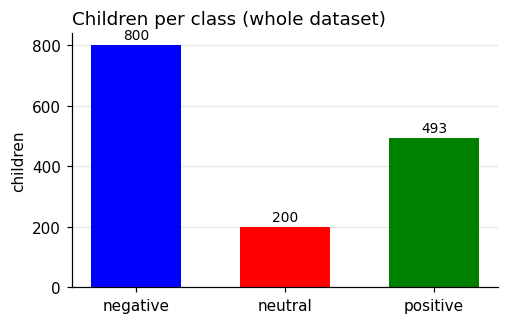

In [4]:
counts = {l: sum(s['label'] == l for s in seqs) for l in LABELS}
for l in LABELS:
    print(f'{l:9s} {counts[l]:4d}  ({counts[l] / len(seqs):.1%})')

fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar(LABELS, [counts[l] for l in LABELS], color=[COLORS[l] for l in LABELS], width=0.6)
ax.bar_label(bars, padding=2, fontsize=9)
ax.set_ylabel('children'); ax.set_title('Children per class (whole dataset)', loc='left')
ax.grid(axis='x', visible=False)
plt.show()

More than half of the children are negative, and neutral is the smallest class (13%). This is the reason the splits fix the train ratio of positive : neutral : negative.

The class also follows the child **id** in blocks. I check that here, because it matters for anything that sorts by id:

In [5]:
for l in LABELS:
    ids = sorted(int(s['id']) for s in seqs if s['label'] == l)
    contiguous = ids == list(range(ids[0], ids[-1] + 1))
    print(f'{l:9s} ids {ids[0]:05d} .. {ids[-1]:05d}   contiguous: {contiguous}')

negative  ids 00493 .. 01292   contiguous: True
neutral   ids 01293 .. 01492   contiguous: True
positive  ids 00000 .. 00492   contiguous: True


Each class is one contiguous block of ids: positive first, then negative, then neutral. So "sorted by id" means "sorted by class".

## 3. The four train / test splits

Each json file has a `TRAIN_SET` and `TEST_SET` list of ids. For each file I check three things that would break an experiment if wrong:

- **leak**: an id in both train and test
- **missing**: an id on disk that is in neither list
- **unknown**: an id in a list that is not on disk

In [6]:
label_of = {s['id']: s['label'] for s in seqs}
split_counts = {}

print(f"{'split':18s} {'set':5s} {'total':>5s} " + ' '.join(f'{l:>9s}' for l in LABELS) + '   leak missing unknown')
for p in SPLITS:
    part = json.load(open(p))
    tr, te = set(part['TRAIN_SET']), set(part['TEST_SET'])
    leak, missing, unknown = len(tr & te), len(set(label_of) - tr - te), len((tr | te) - set(label_of))
    for name, ids in (('train', tr), ('test', te)):
        c = {l: sum(label_of.get(i) == l for i in ids) for l in LABELS}
        split_counts[(p.stem, name)] = c
        extra = f'   {leak:4d} {missing:7d} {unknown:7d}' if name == 'train' else ''
        print(f'{p.stem:18s} {name:5s} {len(ids):5d} ' + ' '.join(f'{c[l]:9d}' for l in LABELS) + extra)

split              set   total  negative   neutral  positive   leak missing unknown
Scoliosis1K_112    train   745       373       186       186      0       0       0
Scoliosis1K_112    test    748       427        14       307
Scoliosis1K_114    train   745       497       124       124      0       0       0
Scoliosis1K_114    test    748       303        76       369
Scoliosis1K_118    train   744       596        74        74      0       0       0
Scoliosis1K_118    test    749       204       126       419
Scoliosis1K_1116   train   745       663        41        41      0       0       0
Scoliosis1K_1116   test    748       137       159       452


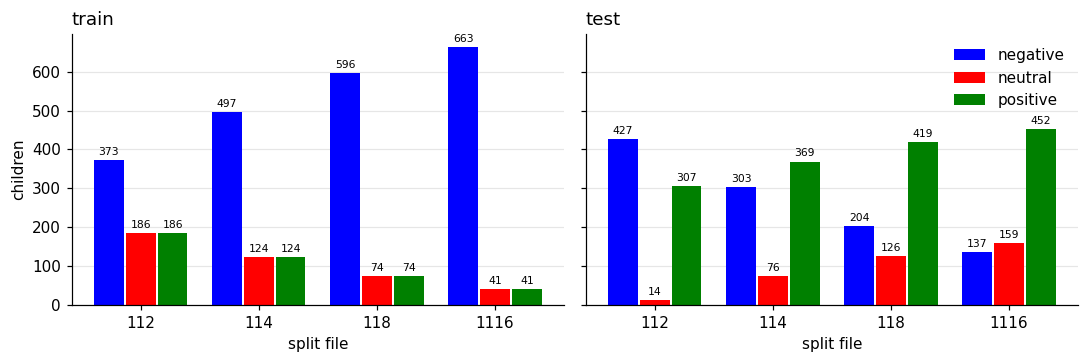

In [7]:
names = [p.stem for p in SPLITS]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, which in zip(axes, ('train', 'test')):
    x = np.arange(len(names)); w = 0.27
    for k, l in enumerate(LABELS):
        bars = ax.bar(x + (k - 1) * w, [split_counts[(n, which)][l] for n in names], w - 0.02,
                      color=COLORS[l], label=l)
        ax.bar_label(bars, padding=2, fontsize=7)
    ax.set_xticks(x, [n.replace('Scoliosis1K_', '') for n in names])
    ax.set_xlabel('split file'); ax.set_title(which, loc='left'); ax.grid(axis='x', visible=False)
axes[0].set_ylabel('children'); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

What I see:

- No split leaks, and every child on disk is used exactly once.
- In **train**, positive = neutral in every file, and negative is 2, 4, 8 or 16 times that. That is what the number in the file name means.
- **Test** is whatever is left over, so its balance is very different from train. In `118` (the one I use) train is 74 / 74 / 596 but test is **204 negative / 126 neutral / 419 positive**: the model is trained mostly on negatives and tested mostly on positives.
- In `112`, only 14 neutral children are left for test, so neutral accuracy on that split is measured on very few children.

Because the test set is so unbalanced, plain accuracy and per-class (macro) numbers can tell different stories. 

## 4. One sequence, frame by frame

I take the first child of each class and show every 25th frame, plus the average of all 300 frames (the gait energy image, GEI).

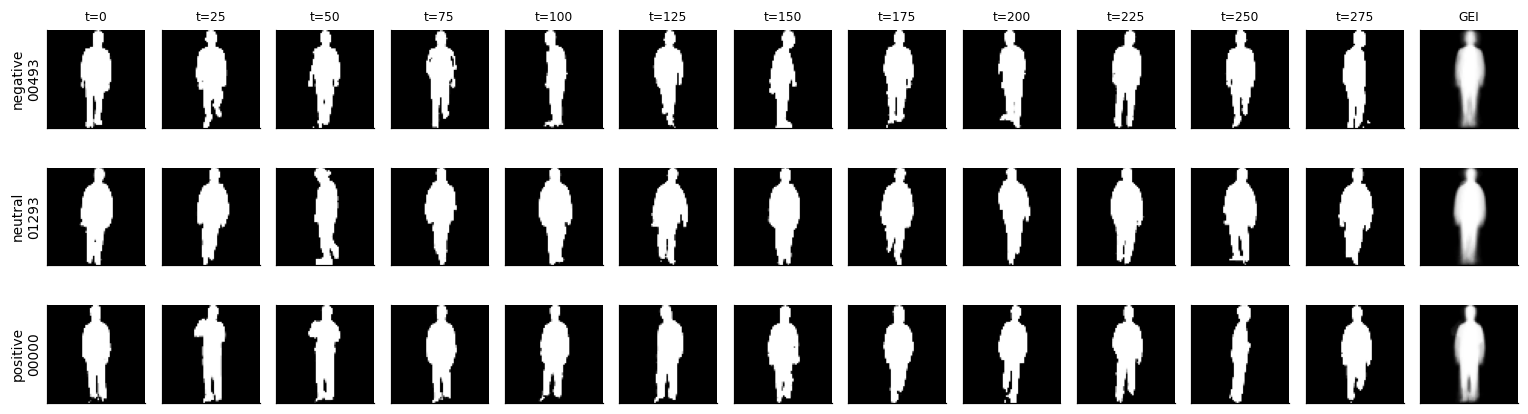

In [8]:
picks = {l: next(s for s in seqs if s['label'] == l) for l in LABELS}
step = 25
fig, axes = plt.subplots(3, 300 // step + 1, figsize=(14, 4.2))
for row, l in enumerate(LABELS):
    x = pickle.load(open(picks[l]['path'], 'rb'))
    for col, t in enumerate(range(0, 300, step)):
        axes[row, col].imshow(x[t], cmap='gray')
        if row == 0: axes[row, col].set_title(f't={t}', fontsize=8)
    axes[row, -1].imshow(x.mean(axis=0), cmap='gray')
    if row == 0: axes[row, -1].set_title('GEI', fontsize=8)
    axes[row, 0].set_ylabel(f"{l}\n{picks[l]['id']}", fontsize=9)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.show()

The silhouettes are already cropped and centred, with the height filling the 64 pixels. Most frames are front or back views (`000_180`), with a few side views where the child turns around, so the GEI looks like a blurred front view of a person.

## 5. Pixel statistics

Two quick checks per sequence: the average share of the 64×64 frame that is body, and how many frames are completely empty (segmentation failure).

In [9]:
fg = {l: np.array([s['fg_mean'] for s in seqs if s['label'] == l]) for l in LABELS}
empty = sum(s['empty_frames'] > 0 for s in seqs)
xc = np.array([s['x_center'] for s in seqs])

for l in LABELS:
    print(f'{l:9s} body share: mean {fg[l].mean():.4f}  std {fg[l].std():.4f}  min {fg[l].min():.4f}  max {fg[l].max():.4f}')
print('sequences with at least one empty frame:', empty)
print(f'horizontal centre of the body (pixels): mean {xc.mean():.2f}  min {xc.min():.2f}  max {xc.max():.2f}')

negative  body share: mean 0.1815  std 0.0103  min 0.1531  max 0.2364
neutral   body share: mean 0.1791  std 0.0087  min 0.1565  max 0.1996
positive  body share: mean 0.1784  std 0.0085  min 0.1542  max 0.2104
sequences with at least one empty frame: 0
horizontal centre of the body (pixels): mean 31.98  min 31.84  max 32.11


About 18% of each frame is body in all three classes, there are no empty frames, and the body is always centred at x = 32 (the middle of 64). So the classes cannot be told apart by size or position alone: whatever the model learns has to come from the shape.

## 6. The average silhouette of each class

I average the GEIs of all children in a class. Then I subtract the negative mean from the other two, so red = more often body in that class, blue = less often.

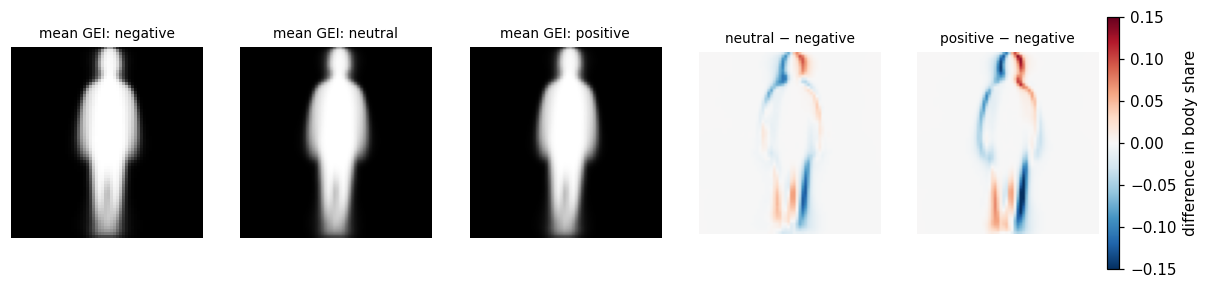

In [10]:
mean_gei = {l: gei_sum[l] / counts[l] for l in LABELS}
fig, axes = plt.subplots(1, 5, figsize=(13, 3))
for ax, l in zip(axes, LABELS):
    ax.imshow(mean_gei[l], cmap='gray', vmin=0, vmax=1); ax.set_title(f'mean GEI: {l}', fontsize=9)
for ax, l in zip(axes[3:], ('neutral', 'positive')):
    im = ax.imshow(mean_gei[l] - mean_gei['negative'], cmap='RdBu_r', vmin=-0.15, vmax=0.15)
    ax.set_title(f'{l} − negative', fontsize=9)
for ax in axes:
    ax.axis('off')
fig.colorbar(im, ax=axes[3:], fraction=0.03, pad=0.02, label='difference in body share')
plt.show()

The three averages look almost the same to the eye, but the difference maps are not empty. Positive minus negative shows paired red / blue bands on the **two sides of the head and shoulders** and **along the legs**: on average, positive children's silhouettes sit a bit differently on the left and right of the body. Neutral − negative shows the same pattern, but weaker.

## 7. Left–right asymmetry per child

Section 6 is an average over hundreds of children. To see if it holds per child, I give each child one number: the mean absolute difference between their GEI and its mirror image, mean |GEI − flip(GEI)|. A perfectly symmetric silhouette gives 0.

negative  asymmetry: median 0.0314  mean 0.0318  std 0.0027
neutral   asymmetry: median 0.0337  mean 0.0339  std 0.0029
positive  asymmetry: median 0.0372  mean 0.0376  std 0.0036
Kruskal-Wallis across the 3 classes: KruskalResult(statistic=660.0235321970686, pvalue=4.761140748647468e-144)


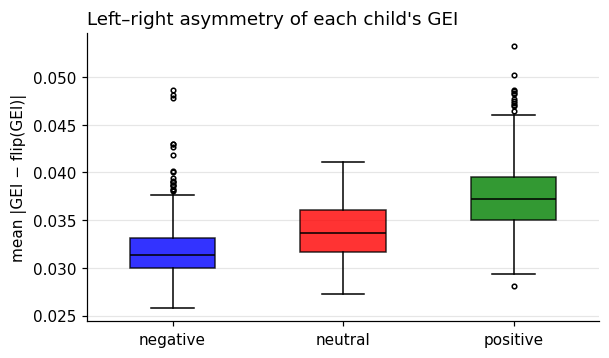

In [11]:
from scipy.stats import kruskal

asym = {l: np.array([s['asym'] for s in seqs if s['label'] == l]) for l in LABELS}
for l in LABELS:
    print(f'{l:9s} asymmetry: median {np.median(asym[l]):.4f}  mean {asym[l].mean():.4f}  std {asym[l].std():.4f}')
print('Kruskal-Wallis across the 3 classes:', kruskal(*asym.values()))

fig, ax = plt.subplots(figsize=(6, 3.4))
bp = ax.boxplot([asym[l] for l in LABELS], tick_labels=LABELS, patch_artist=True, widths=0.5,
                medianprops=dict(color='k'), flierprops=dict(markersize=3))
for patch, l in zip(bp['boxes'], LABELS):
    patch.set_facecolor(COLORS[l]); patch.set_alpha(0.8)
ax.set_ylabel('mean |GEI − flip(GEI)|'); ax.set_title('Left–right asymmetry of each child\'s GEI', loc='left')
ax.grid(axis='x', visible=False)
plt.show()

The order is negative < neutral < positive, and the Kruskal–Wallis test (do the three groups come from the same distribution?) says the difference is far too large to be chance. But the boxes still **overlap a lot**: many positive children are less asymmetric than many negative children. So one hand-made number is not enough to classify a child. A learned model has to pick up more than this.

## What I learned about the data

| Question | Answer |
|---|---|
| How much data? | 1,493 children, one sequence each, one view (`000_180`) |
| Shape of a sequence | always 300 × 64 × 64, binary (0 / 255), no empty frames |
| Classes | negative 800 (53.6%), positive 493 (33.0%), neutral 200 (13.4%) |
| Ids | each class is one contiguous id block: positive 0–492, negative 493–1292, neutral 1293–1492 |
| Splits | 4 files, no leaks; train is 1:1:k, test is the remainder and is very different from train |
| Split I use (`118`) | train 596 / 74 / 74, test 204 / 126 / 419 (negative / neutral / positive) |
| Size and position | the same in every class (=18% body, centred at x = 32) |
| Where the classes differ | left–right differences at the head/shoulders and legs, strongest for positive; clear on average but overlapping per child |